In [306]:
# ==============================================================================
# Import modules
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import warnings 
warnings.filterwarnings('ignore') 

In [307]:
# ==============================================================================
# Load data and select features
# ==============================================================================
data = pd.read_csv("./fetal_health.csv", index_col=0)

var = range(data.shape[1])
var_names=data.columns
print(var_names)
print(data.shape)
X = data.drop(columns=['fetal_health','baseline value','histogram_mean', 'histogram_variance'])
y = data['fetal_health']
feature_names=X.columns
print(X.shape)

Index(['baseline value', 'accelerations', 'prolongued_decelerations',
       'abnormal_short_term_variability',
       'mean_value_of_short_term_variability',
       'percentage_of_time_with_abnormal_long_term_variability',
       'histogram_mean', 'histogram_variance', 'fetal_health'],
      dtype='object')
(1290, 9)
(1290, 5)


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'accelerations'),
  Text(1, 0, 'prolongued_decelerations'),
  Text(2, 0, 'abnormal_short_term_variability'),
  Text(3, 0, 'mean_value_of_short_term_variability'),
  Text(4, 0, 'percentage_of_time_with_abnormal_long_term_variability'),
  Text(5, 0, 'target')])

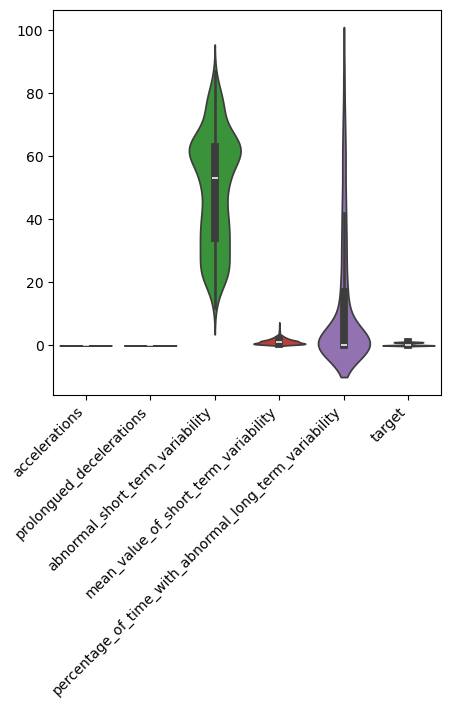

In [308]:
# ==============================================================================
# Violin plot of input data to inspect distribution of features
# ==============================================================================
fig, ax = plt.subplots(1, 1, figsize=(5, 5))  # figure size 5x5
df = pd.DataFrame(X, columns=feature_names)  # data into a pandas data frame
df["target"] = y  # target column
sns.violinplot(data=df, ax=ax)
plt.xticks(rotation=45, ha='right')

Class labels: [0 1]
Classifier: Perceptron(eta0=0.05, max_iter=100, random_state=101)
Average test accuracy across 100 splits for Perceptron is 0.823 +/- 0.062
Average train accuracy across 100 splits for Perceptron is 0.827 +/- 0.059
Time used for Perceptron is 0.280
Classifier: LogisticRegression(penalty=None, random_state=102, tol=0.001)
Average test accuracy across 100 splits for Logistic Regression is 0.882 +/- 0.019
Average train accuracy across 100 splits for Logistic Regression is 0.885 +/- 0.008
Time used for Logistic Regression is 0.404
Classifier: SGDClassifier(eta0=0.05, learning_rate='constant', loss='squared_error',
              max_iter=100, penalty=None, random_state=103)
Average test accuracy across 100 splits for Adaline is 0.849 +/- 0.036
Average train accuracy across 100 splits for Adaline is 0.848 +/- 0.034
Time used for Adaline is 0.315
Most accurate classifier across 100 splits: Logistic Regression
Fastest classifier: Perceptron


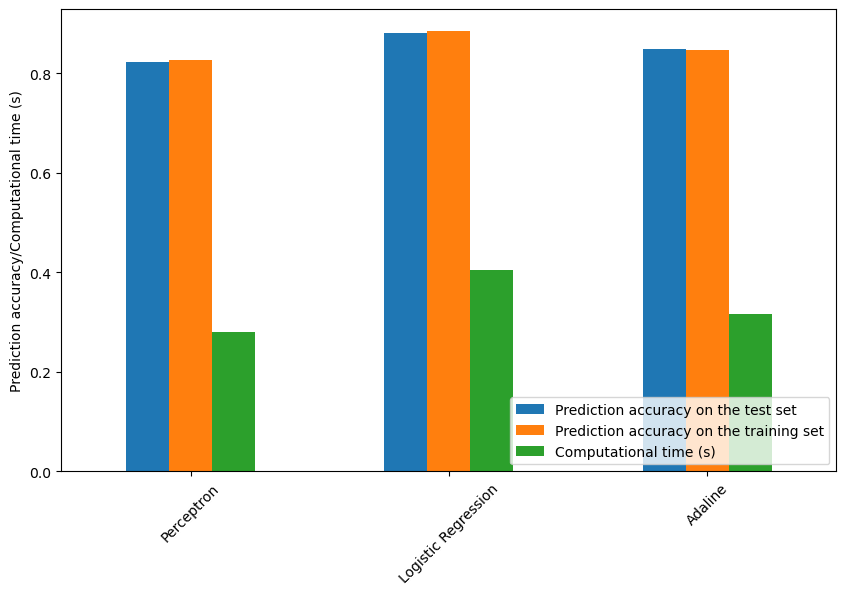

In [309]:

# ==============================================================================
# Split into training and test data
# ==============================================================================

# Print lables of all classes in data set
print("Class labels:", np.unique(y))

#Split into a training set and a (final) test set that will be used for a final testing after comparison of alternative models
X_train_tot, X_test_final, y_train_tot, y_test_final = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y) 

# Initialise standard scaler and the classification models
sc = StandardScaler()
ppn = Perceptron(eta0=0.05, max_iter=100, tol=1e-3, random_state=101)
logreg = LogisticRegression(max_iter=100, tol=1e-3, random_state=102, penalty=None)  
ada = SGDClassifier(loss='squared_error', eta0=0.05, max_iter=100, tol=1e-3, random_state=103, penalty=None, learning_rate='constant') #Gives Adaline

Test_acc={}
Train_acc={}
Time={}
for clf, model in zip([ppn, logreg, ada],['Perceptron','Logistic Regression','Adaline']):
    print(f"Classifier: {clf}")
    
    test_accuracies = []
    train_accuracies = []
    t_start=time.time()
    for seed in range(1,101):
        # Split data into training and test data (70% training, 30% test)
        X_train, X_test, y_train, y_test = train_test_split(X_train_tot, y_train_tot, test_size=0.3, random_state=seed, stratify=y_train_tot)

        #Compute the mean and STD from the training data
        sc.fit(X_train)

        # Transform (standardise) both X_train and X_test with the mean and stddev from
        # the training data
        X_train_sc = sc.transform(X_train)
        X_test_sc = sc.transform(X_test)

        # Fit the classification model
        clf.fit(X_train_sc, y_train)

        # Calculate the prediction accuracy for the training set and the test set
        test_score = clf.score(X_test_sc, y_test)
        train_score = clf.score(X_train_sc, y_train)
        test_accuracies.append(test_score)
        train_accuracies.append(train_score)

    time_used=time.time()-t_start # Time used for 100 model training runs
    
        
    print(
        f"Average test accuracy across 100 splits for {model}"
        f" is {np.mean(test_accuracies):.3f} +/- {np.std(test_accuracies):.3f}"
    )
    
    print(
        f"Average train accuracy across 100 splits for {model}"
        f" is {np.mean(train_accuracies):.3f} +/- {np.std(train_accuracies):.3f}"
    )

    print(
        f"Time used for {model}"
        f" is {time_used:.3f}"
    )

    Test_acc[model]=np.mean(test_accuracies)
    Train_acc[model]=np.mean(train_accuracies)
    Time[model]=time_used

print(f"Most accurate classifier across 100 splits: {max(Test_acc, key=Test_acc.get)}")
print(f"Fastest classifier: {min(Time, key=Time.get)}")

# Create bar plots of accuracies and computational times

df = pd.DataFrame({'Prediction accuracy on the test set': Test_acc, 'Prediction accuracy on the training set': Train_acc, 'Computational time (s)': Time})

# Plot as a grouped bar chart
df.plot(kind='bar', figsize=(10, 6))
plt.ylabel('Prediction accuracy/Computational time (s)')
plt.xticks(rotation=45) 
plt.legend(loc='lower right')
plt.show()



In [310]:

# =================================================================================================================================
# Train a final model with the best method found above, and make a final prediction for the test set that has been kept out so far
# =================================================================================================================================
most_accurate_clf=max(Test_acc, key=Test_acc.get)

if most_accurate_clf=='Perceptron':
    use_clf=ppn
elif most_accurate_clf=='Logistic Regression':
    use_clf=logreg
else:
    use_clf=ada
    
# Standardise the data with parameters found using the total training set
sc.fit(X_train_tot)

X_train_tot_sc = sc.transform(X_train_tot)
X_test_final_sc = sc.transform(X_test_final)

# Fit the best model on the entire training set
use_clf.fit(X_train_tot_sc, y_train_tot)

# Predict classes for samples in the final test set and print the number of misclassfications
y_pred_final = use_clf.predict(X_test_final_sc)
print("Misclassified samples in the final test set: {0}".format((y_test_final != y_pred_final).sum()))


# ==============================================================================
# Compute performance metrics
# ==============================================================================

# Print accuracy computed from predictions on the test set
print("Accuracy for the final test set: {0:.2f}".format(accuracy_score(y_test_final, y_pred_final)))


# Print accuracy computed from predictions on the test set
print("Accuracy for the final test set: {0:.2f}".format(use_clf.score(X_test_final_sc, y_test_final)))

Misclassified samples in the final test set: 52
Accuracy for the final test set: 0.87
Accuracy for the final test set: 0.87
